In [17]:
import re
import os
import pandas as pd
import seaborn as sns
import joblib
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.model_selection import train_test_split

In [18]:
# Importing dataset
df=pd.read_csv(r"../data/emails.csv")

In [19]:
# Exploring the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5728 entries, 0 to 5727
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    5728 non-null   str  
 1   spam    5728 non-null   int64
dtypes: int64(1), str(1)
memory usage: 89.6 KB


In [20]:
df.sample(10)

,text,spam
4424,Subject: vacation carryover want to verify yo...,0
5158,Subject: fortnightly on - line dear mr . kami...,0
5225,Subject: re : the newvatrfacs program and test...,0
150,"Subject: when we say free , we mean free ! to...",1
653,Subject: are you ready to get it ? hello ! v...,1
1690,Subject: thanks vince : thanks for the time ...,0
1114,Subject: naturally irresistible your corporate...,1
2353,Subject: introduction of the european gas advi...,0
2259,Subject: it compliance after 23 years of serv...,0
2557,"Subject: re : test thanks , vince . we have r...",0


In [21]:
# Computing exact label ratios
df['spam'].value_counts(normalize=True)

spam
0    0.761173
1    0.238827
Name: proportion, dtype: float64

<Axes: xlabel='spam', ylabel='Count'>

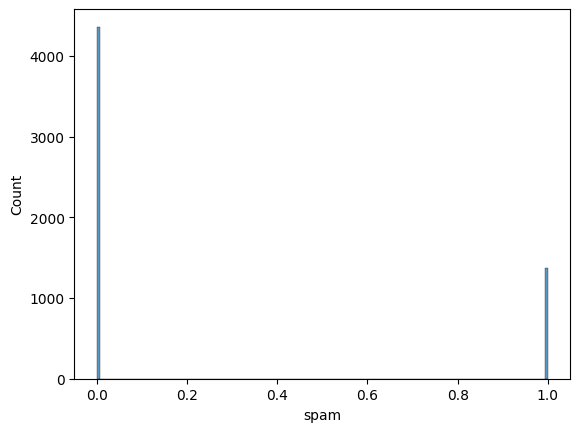

In [22]:
sns.histplot(df['spam'])

In [23]:
# Robust text processing function
stop_words=set(ENGLISH_STOP_WORDS)
def clean_raw_text(raw_text):
    if not isinstance(raw_text, str):
        return ""
    
    lowercase_text=raw_text.lower()
    stripped_text=re.sub(r'[^a-zA-Z\s]', '', lowercase_text)
    tokens=stripped_text.split()
    meaningful_words=[word for word in tokens if word not in stop_words]
    return " ".join(meaningful_words)


In [24]:
# Applying the processing pipeline to the text matrix
df['text']=df['text'].apply(clean_raw_text)

In [25]:
# Stratified Train-Test Split to safeguard against class distribution leakage
X=df['text']
y=df['spam']
X_train, X_test, y_train, y_test=train_test_split(X, y, random_state=42, stratify=y)

In [26]:
vectorizer=TfidfVectorizer(max_features=3000)
X_train_tdidf=vectorizer.fit_transform(X_train).toarray()
X_test_tfidf=vectorizer.transform(X_test).toarray()

In [27]:
os.makedirs("../model", exist_ok=True)
os.makedirs("../notebook", exist_ok=True)

In [28]:
# Exporting target columns
pd.DataFrame(y_train).to_csv("../data/y_train.csv", index=False)
pd.DataFrame(y_test).to_csv("../data/y_test.csv", index=False)
# Exporting Cleaned text columns
pd.DataFrame(X_train).to_csv("../data/X_train.csv", index=False)
pd.DataFrame(X_test).to_csv("../data/X_test.csv", index=False)

In [29]:
# Exporting the fitted vectorizer object
joblib.dump(vectorizer, "../model/text_vectorizer.joblib")
print("!! Successfully Exported Text Vectorizer !!")

!! Successfully Exported Text Vectorizer !!
